In [1]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import math

# Set style untuk visualisasi
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

In [2]:
from pathlib import Path
# Load data mentah dari Excel (sheet "Full Data")
file_path = Path.cwd().parent / "data" / "credit_risk_survey.xlsx"
df = pd.read_excel(file_path, sheet_name="Full Data")
df.head()

,IDR,IDR1,No Bank,Nama,C11,c11d1,c11d2,C12,C21,C22,...,X17.1.1,X17.1.2,X17.2.1,X17.2.2,X17.3.1,X17.3.2,Y4.1.1,Y4.1.2,Y4.2.1,Y4.2.2
0,1,1,1,Bank XA,2,1,0,5.0,8,16,...,5,4,5,3,2,2,1,3,3,3
1,2,2,1,Bank XA,2,1,0,4.5,8,16,...,3,2,4,3,3,4,3,4,3,3
2,3,3,1,Bank XA,2,1,0,2.5,8,16,...,3,1,4,5,1,3,3,2,2,3
3,4,4,1,Bank XA,3,0,1,12.5,8,16,...,5,3,4,4,3,4,3,4,5,2
4,5,5,1,Bank XA,3,0,1,8.0,2,12,...,1,5,3,4,2,3,3,4,3,3


In [3]:
# Cek ukuran data (jumlah baris dan kolom)
print("=== SHAPE DATA ===")
print("Baris, Kolom:", df.shape)

# Lihat beberapa nama kolom pertama
print("\n=== CONTOH NAMA KOLOM PERTAMA ===")
print(df.columns[:15].tolist())

# Check missing value
missing_total = df.isna().sum().sum()
print("\n=== MISSING VALUE DALAM SHEET FULL DATA ===")
print("Total Missing Value:", missing_total)

# Distribusi Z(cat) (target kolektabilitas mentah)
print("\n=== DISTRIBUSI Z (cat) ===")
print(df["Z (cat)"].value_counts(dropna=False))

=== SHAPE DATA ===
Baris, Kolom: (2700, 204)

=== CONTOH NAMA KOLOM PERTAMA ===
['IDR', 'IDR1', 'No Bank', 'Nama', 'C11', 'c11d1', 'c11d2', 'C12', 'C21', 'C22', 'C23', 'C24', 'C25', 'C31', 'C32']

=== MISSING VALUE DALAM SHEET FULL DATA ===
Total Missing Value: 0

=== DISTRIBUSI Z (cat) ===
Z (cat)
1    2267
2     400
3      15
4      10
5       8
Name: count, dtype: int64


In [4]:
# Mapping Z(cat) → PL / NPL (primer)
def pl_npl_label(z):
    if z in [1, 2]:
        return "PL"   # Performing Loan
    elif z in [3, 4, 5]:
        return "NPL"  # Non-Performing Loan
    else:
        return None

df["status_group"] = df["Z (cat)"].apply(pl_npl_label)

# Hitung jumlah tiap kelas
count_status = df["status_group"].value_counts()
percent_status = (count_status / len(df) * 100).round(2)

print("=== DISTRIBUSI KELAS PL vs NPL ===")
print(count_status)
print("\n=== PERSENTASE PL vs NPL ===")
print(percent_status)

# Pastikan Z(day) numeric
df["Z (day)"] = pd.to_numeric(df["Z (day)"], errors="coerce")

# Buat bin untuk Z(day)
bins = [0, 90, 120, 180, 999999]  # 0-90, 91-120, 121-180, >180
labels = ["0-90", "91-120", "121-180", ">180"]

df["Zday_group"] = pd.cut(
    df["Z (day)"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Hitung jumlah dan persentase tiap kelompok
zday_counts = df["Zday_group"].value_counts().sort_index()
zday_percent = (zday_counts / len(df) * 100).round(2)

print("=== DISTRIBUSI Z(day) BERDASARKAN INTERVAL HARI ===")
print(zday_counts)

print("\n=== PERSENTASE Z(day) BERDASARKAN INTERVAL HARI ===")
print(zday_percent)

=== DISTRIBUSI KELAS PL vs NPL ===
status_group
PL     2667
NPL      33
Name: count, dtype: int64

=== PERSENTASE PL vs NPL ===
status_group
PL     98.78
NPL     1.22
Name: count, dtype: float64
=== DISTRIBUSI Z(day) BERDASARKAN INTERVAL HARI ===
Zday_group
0-90       2667
91-120       15
121-180      10
>180          8
Name: count, dtype: int64

=== PERSENTASE Z(day) BERDASARKAN INTERVAL HARI ===
Zday_group
0-90       98.78
91-120      0.56
121-180     0.37
>180        0.30
Name: count, dtype: float64



===== Distribusi Data per Bank =====
Nama
Bank XE    800
Bank XA    500
Bank XB    500
Bank XC    500
Bank XD    400
Name: count, dtype: int64


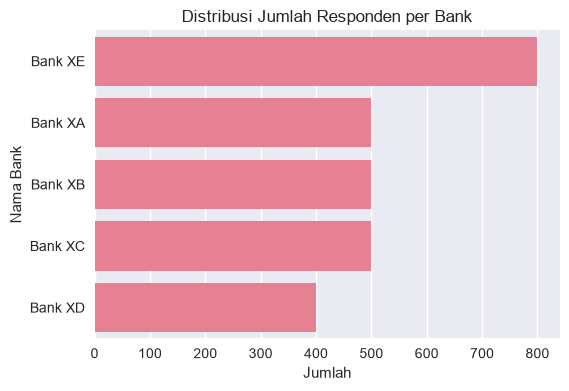

In [5]:
# --- SEBARAN BANK ---
print("\n===== Distribusi Data per Bank =====")
print(df["Nama"].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(y="Nama", data=df, order=df["Nama"].value_counts().index)
plt.title("Distribusi Jumlah Responden per Bank")
plt.xlabel("Jumlah")
plt.ylabel("Nama Bank")
plt.show()

<tmp>\ipykernel_12064\2355754539.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_12064\2355754539.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_12064\2355754539.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
<tmp>\ipykernel_12064\2355754539.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. 

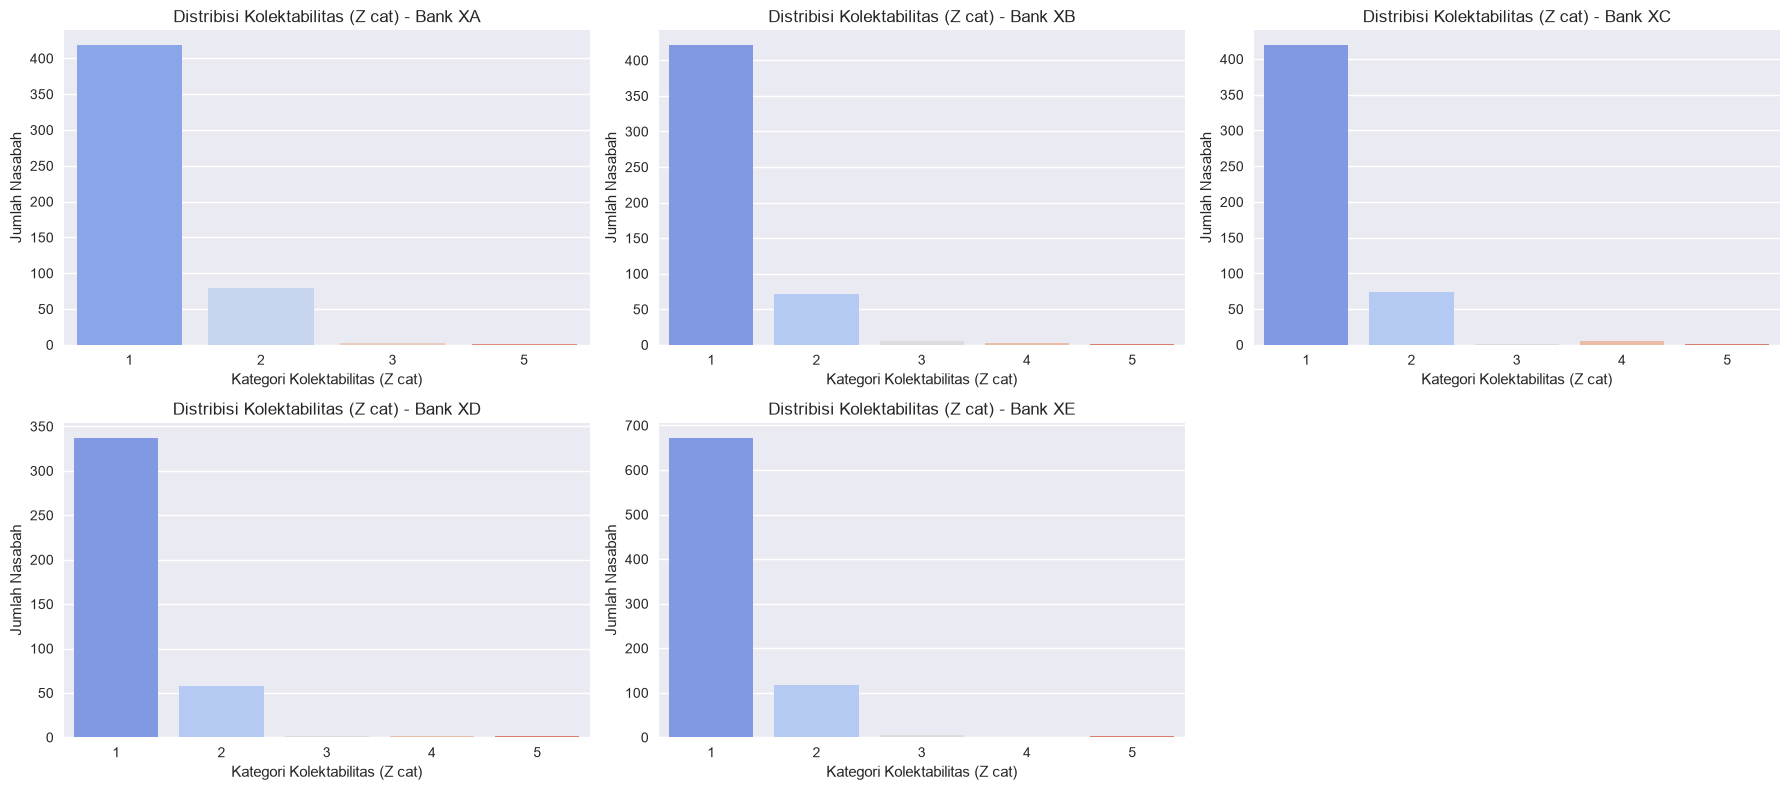

In [6]:
# --- Daftar semua bank ---
banks = sorted(df["Nama"].unique())
n_banks = len(banks)

# --- Tentukan grid ukuran (misalnya 3 kolom) ---
cols = 3
rows = math.ceil(n_banks / cols)

plt.figure(figsize=(6*cols, 4*rows))

# --- Plot untuk setiap bank ---
for i, bank in enumerate(banks, start=1):
    plt.subplot(rows, cols, i)
    subset = df[df["Nama"] == bank]
    sns.countplot(x="Z (cat)", data=subset, palette="coolwarm")
    plt.title(f"Distribisi Kolektabilitas (Z cat) - {bank}")
    plt.xlabel("Kategori Kolektabilitas (Z cat)")
    plt.ylabel("Jumlah Nasabah")

plt.tight_layout()
plt.show()

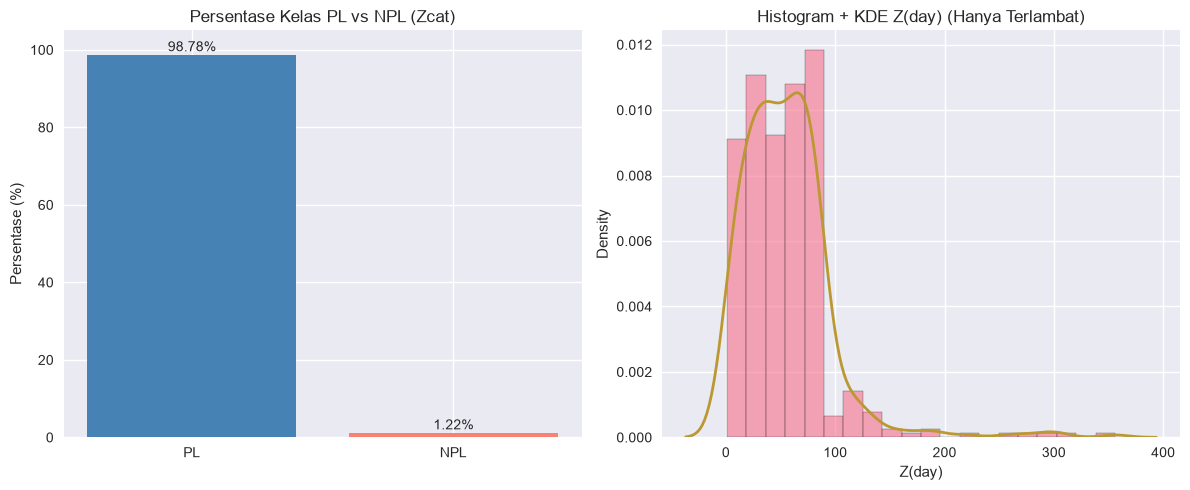

In [7]:
plt.figure(figsize=(12, 5))

# ---- Subplot 1: PL vs NPL ----
plt.subplot(1, 2, 1)
bars1 = plt.bar(percent_status.index, percent_status.values, color=['steelblue', 'salmon'])
plt.title("Persentase Kelas PL vs NPL (Zcat)")
plt.ylabel("Persentase (%)")

for bar in bars1:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.1,
             f"{height:.2f}%", ha='center', va='bottom')

plt.ylim(0, 105)



# ---- Subplot 2: Histogram + KDE Z(day) ----
plt.subplot(1, 2, 2)

# Filter hanya yang terlambat
late_days = df[df["Z (day)"] != 0]["Z (day)"].dropna()

# Histogram default color
plt.hist(late_days, bins=20, edgecolor='black', density=True, alpha=0.6)

# Tambahkan KDE (hanya jika data lebih dari 1 agar tidak error)
if len(late_days) > 1:
    sns.kdeplot(late_days, linewidth=2)

plt.title("Histogram + KDE Z(day) (Hanya Terlambat)")
plt.xlabel("Z(day)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()



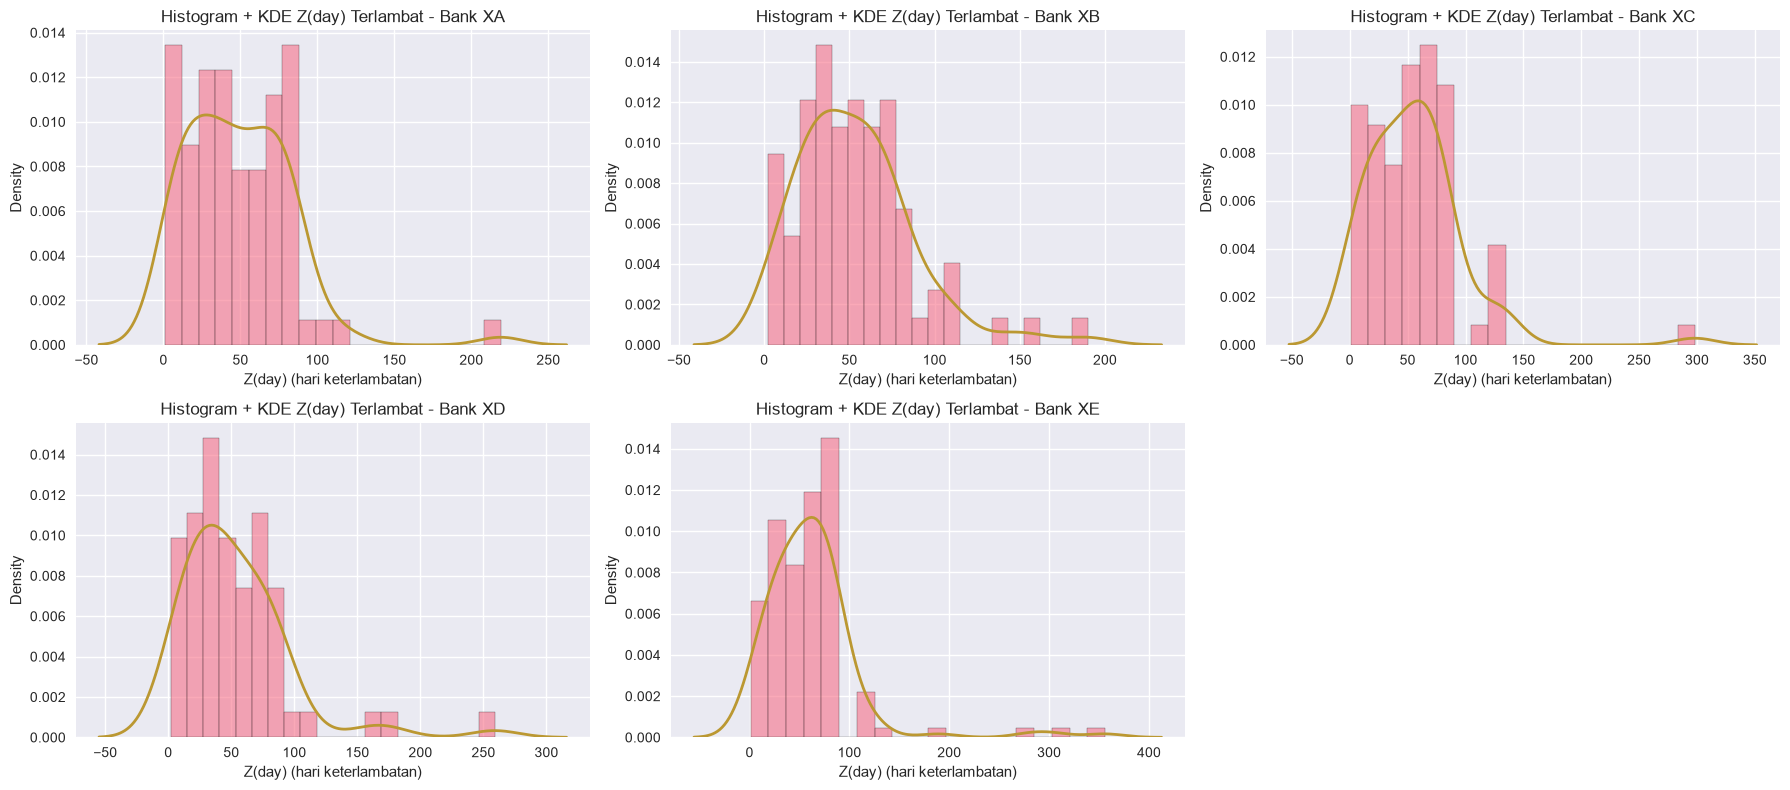

In [8]:

# ======================================================
#     HISTOGRAM + KDE Z(day) PER BANK — TERLAMBAT SAJA
# ======================================================

plt.figure(figsize=(6*cols, 4*rows))

for i, bank in enumerate(banks, start=1):
    plt.subplot(rows, cols, i)
    subset = df[df["Nama"] == bank]

    # Hanya yang terlambat (Z(day) != 0)
    late_subset = subset[subset["Z (day)"] != 0]["Z (day)"].dropna()

    # Histogram (warna default)
    plt.hist(
        late_subset,
        bins=20,
        density=True,       # supaya KDE sebanding dengan histogram
        edgecolor='black',
        alpha=0.6
    )

    # KDE (garis halus)
    if len(late_subset) > 1:
        sns.kdeplot(late_subset, linewidth=2)

    plt.title(f"Histogram + KDE Z(day) Terlambat - {bank}")
    plt.xlabel("Z(day) (hari keterlambatan)")
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [9]:
# ======================================
# Ambil hanya variabel X dan Y (primer)
# ======================================
x_cols = [c for c in df.columns if c.startswith("X")]
y_cols = [c for c in df.columns if c.startswith("Y")]

print("\n=== INFORMASI VARIABEL X & Y ===")
print("Jumlah variabel X:", len(x_cols))
print("Contoh nama X:", x_cols[:15])
print("Jumlah variabel Y:", len(y_cols))
print("Contoh nama Y:", y_cols[:10])

# Sub-dataframe khusus X dan Y
X_raw = df[x_cols]
Y_raw = df[y_cols]

# ======================================
# Cek missing value di X dan Y
# ======================================
missing_total_X = X_raw.isna().sum().sum()
missing_total_Y = Y_raw.isna().sum().sum()

print("\n=== MISSING VALUE DI VARIABEL X ===")
print("Total missing di semua kolom X:", missing_total_X)

print("\n=== MISSING VALUE DI VARIABEL Y ===")
print("Total missing di semua kolom Y:", missing_total_Y)

# ======================================
# tatistik deskriptif awal variabel X
# ======================================
print("\n=== STATISTIK DESKRIPTIF VARIABEL X (5 pertama) ===")
print(X_raw.describe().T.head())


=== INFORMASI VARIABEL X & Y ===
Jumlah variabel X: 130
Contoh nama X: ['X1.1.1', 'X1.1.2', 'X1.2.1', 'X1.2.2', 'X1.3.1', 'X1.3.2', 'X1.4.1', 'X1.4.2', 'X1.5.1', 'X1.5.2', 'X2.1.1', 'X2.1.2', 'X2.2.1', 'X2.2.2', 'X3.1.1']
Jumlah variabel Y: 26
Contoh nama Y: ['Y1.1.1', 'Y1.1.2', 'Y1.2.1', 'Y1.2.2', 'Y1.3.1', 'Y1.3.2', 'Y1.4.1', 'Y1.4.2', 'Y1.5.1', 'Y1.5.2']

=== MISSING VALUE DI VARIABEL X ===
Total missing di semua kolom X: 0

=== MISSING VALUE DI VARIABEL Y ===
Total missing di semua kolom Y: 0

=== STATISTIK DESKRIPTIF VARIABEL X (5 pertama) ===
         count      mean       std  min  25%  50%  75%  max
X1.1.1  2700.0  3.421481  1.105135  1.0  3.0  4.0  4.0  5.0
X1.1.2  2700.0  3.440370  1.108992  1.0  3.0  4.0  4.0  5.0
X1.2.1  2700.0  3.431111  1.101750  1.0  3.0  4.0  4.0  5.0
X1.2.2  2700.0  3.445926  1.088031  1.0  3.0  4.0  4.0  5.0
X1.3.1  2700.0  3.440000  1.107635  1.0  3.0  4.0  4.0  5.0


In [10]:
# Hitung nilai unique Z(day) dan frekuensinya
zday_freq = df["Z (day)"].value_counts(dropna=False)

# Tampilkan hasil
print("=== Nilai Unique Z(day) Berdasarkan Frekuensi ===")
print(zday_freq)


=== Nilai Unique Z(day) Berdasarkan Frekuensi ===
Z (day)
0      2267
56       11
23        9
79        8
69        8
       ... 
189       1
114       1
18        1
304       1
115       1
Name: count, Length: 119, dtype: int64


In [11]:
# Pastikan target survival
target = "Z (day)" if "Z (day)" in df.columns else "Z (days)"

# Event column (tanpa censoring → semua event terjadi)
df["event"] = 1

# ---------------------------
# REMOVE Kolom yang diminta
# ---------------------------
remove = ["IDR", "IDR1", "No Bank", "Z (cat)"]

# Hapus seluruh fitur yang diawali huruf "C" (contoh: C1, C2, C3 ...)
cols_C = [col for col in df.columns if col.startswith("C")]
remove = remove + cols_C

df_clean = df.drop(columns=remove, errors="ignore")

In [12]:
import pandas as pd
import numpy as np
from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
# Hanya gunakan fitur numerik
feature_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

# Hilangkan target & event dari fitur
feature_cols = [col for col in feature_cols if col not in [target, "event"]]

# Dataset final untuk survival model
df_sa = df_clean[[target, "event"] + feature_cols]

print("===== Kolom digunakan Survival Analysis =====")
print(df_sa.head())
print("\nJumlah fitur:", len(feature_cols))

===== Kolom digunakan Survival Analysis =====
   Z (day)  event  c11d1  c11d2  X1.1.1  X1.1.2  X1.2.1  X1.2.2  X1.3.1  \
0        0      1      1      0       5       4       4       3       3   
1        0      1      1      0       3       2       2       3       2   
2       59      1      1      0       2       5       2       4       4   
3        0      1      0      1       3       3       4       1       2   
4        0      1      0      1       2       4       1       3       2   

   X1.3.2  ...  X17.1.1  X17.1.2  X17.2.1  X17.2.2  X17.3.1  X17.3.2  Y4.1.1  \
0       3  ...        5        4        5        3        2        2       1   
1       3  ...        3        2        4        3        3        4       3   
2       5  ...        3        1        4        5        1        3       3   
3       4  ...        5        3        4        4        3        4       3   
4       3  ...        1        5        3        4        2        3       3   

   Y4.1.2  Y4.2.1  Y4.

In [14]:
# =====================================
# 2. Event & Time
# =====================================

# event = 1 jika Z(cat) > 2
df["event"] = df["Z (cat)"].apply(lambda x: 0 if x in [1, 2] else 1)

# time = Z(day)
df["time"] = df["Z (day)"]


In [15]:
# =====================================
# 3. Drop kolom yang diminta + semua C*
# =====================================

# kolom spesifik
remove_cols = ["IDR", "IDR1", "No Bank", "Z (cat)", "c11d1", "c11d2"]

# kolom yang diawali huruf C
cols_C = [col for col in df.columns if col.startswith("C")]

# gabungkan
remove_cols = remove_cols + cols_C

df.drop(columns=remove_cols, inplace=True, errors="ignore")

# KM butuh time > 0
df = df[df["time"] > 0]

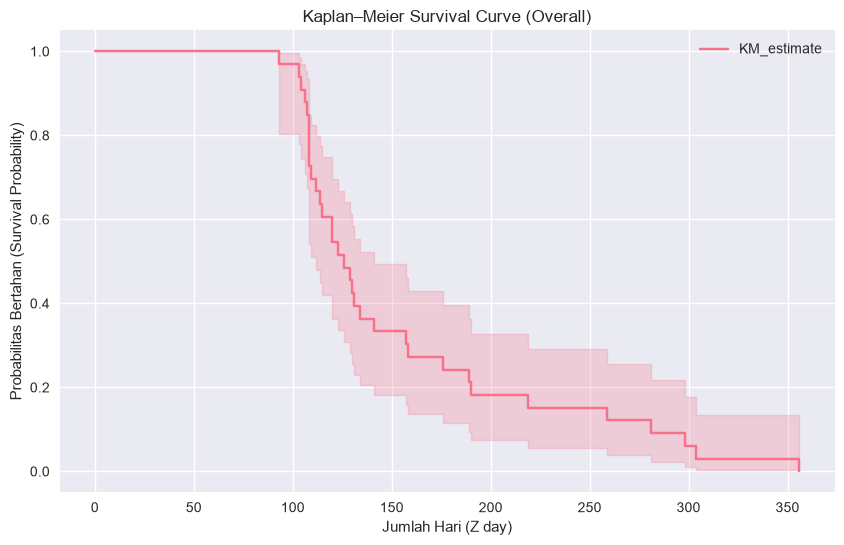

In [16]:
# =====================================
# 4. Kaplan–Meier Overall
# =====================================
km = KaplanMeierFitter()

km.fit(durations=df["time"], event_observed=df["event"])

plt.figure(figsize=(10,6))
km.plot(ci_show=True)
plt.title("Kaplan–Meier Survival Curve (Overall)")
plt.xlabel("Jumlah Hari (Z day)")
plt.ylabel("Probabilitas Bertahan (Survival Probability)")
plt.grid(True)
plt.show()

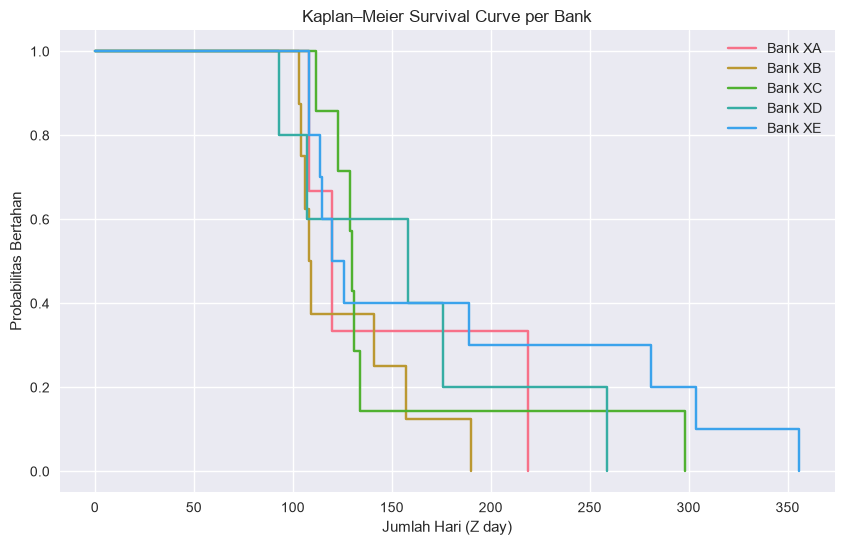

In [17]:
# =====================================
# 5. Kaplan–Meier per Nama Bank
# =====================================
plt.figure(figsize=(10,6))

for bank in df["Nama"].unique():
    mask = df["Nama"] == bank
    km.fit(df["time"][mask], df["event"][mask], label=f"{bank}")
    km.plot(ci_show=False)

plt.title("Kaplan–Meier Survival Curve per Bank")
plt.xlabel("Jumlah Hari (Z day)")
plt.ylabel("Probabilitas Bertahan")
plt.legend(loc="best")
plt.grid(True)
plt.show()